# 〰️ 03 · The Sigmoid Unit and Non-linearity

> **Module 01 – Perceptron and Gradient Descent** · Notebook 3 of 3
> Course notes: *"Cannot build complex NN with thresholded perceptron… Network of linear neurons will have same effect as a single neuron. Need non-linear, cont., diff., should simulate activation of neuron ⇒ Sigmoid"* (page 3) · Mitchell §4.5.1

We now have two half-solutions:
* the **step** neuron (notebook 01) is non-linear but has no slope → can't be trained inside a network;
* the **linear** neuron (notebook 02) has a slope but stacking linear neurons is pointless → still one straight line.

The **sigmoid** keeps the best of both: it is *step-like* **and** *smooth*. With it, networks become both **powerful** and **trainable** – the foundation for backpropagation in module 02.

### 🎯 What you will learn

| # | Idea |
|---|---|
| 1 | **Why stacked linear layers collapse** into one layer (proof + code) |
| 2 | The three requirements for a good activation function |
| 3 | The sigmoid $\sigma(x)=\frac{1}{1+e^{-x}}$ and its beautiful derivative $\sigma'(x)=y(1-y)$ |
| 4 | Gradient descent for a **sigmoid unit** (learning OR) |
| 5 | Why a single sigmoid still fails XOR, and how **one hidden layer** fixes it |
| 6 | A first look at the **vanishing gradient** ($\sigma'\le 0.25$) |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
POINT_CMAP = ListedColormap([C["blue"], C["orange"]])
np.set_printoptions(precision=4, suppress=True)

---
## 1 · The variables 📖

| Symbol | Meaning | Example |
|---|---|---|
| $\vec x$ | input vector (with bias $x_0=1$) | $(1,\ 0,\ 1)$ |
| $\vec w$ | weights of one unit | $(-2,\ 5,\ 5)$ |
| $net=\vec w\cdot\vec x$ | net input (weighted sum) | $3$ |
| $\sigma(\cdot)$ | the **sigmoid** (logistic) function | – |
| $o=\sigma(net)$ | output of a sigmoid unit, always in $(0,1)$ | $0.953$ |
| $y$ | the notes write $y=\sigma(x)$ for the sigmoid's output | – |
| $t_d,\ o_d$ | target and output for example $d$ | $1,\ 0.953$ |
| $E=\tfrac12\sum_d(t_d-o_d)^2$ | squared-error cost (same as notebook 02) | – |
| $W_1, W_2$ | weight **matrices** of two stacked layers (each row = one neuron's weights) | $4\times3$, $2\times4$ |
| $\vec h$ | vector of hidden-layer outputs | – |

---
## 2 · Why stacking linear neurons is pointless 🥞

Take two layers of linear neurons. Layer 1 turns $\vec x$ into $\vec h=W_1\vec x$, and layer 2 turns $\vec h$ into $\vec o=W_2\vec h$. Substitute:

$$\vec o=W_2\ (W_1\vec x)=(W_2W_1)\ \vec x=W_3\ \vec x\qquad\text{where }W_3=W_2W_1$$

A product of two matrices is **just another matrix**. So the 2-layer network is *exactly* a 1-layer network with weights $W_3$. Ten layers? Still one matrix. **Still one straight line.**

*Everyday analogy:* doubling a number and then tripling it is the same as multiplying by 6 once.

In [2]:
rng = np.random.default_rng(42)
X = rng.normal(size=(3, 10))          # 10 examples as COLUMNS, 3 features each
W1 = rng.normal(size=(4, 3))          # layer 1: 4 neurons, each looks at 3 inputs
W2 = rng.normal(size=(2, 4))          # layer 2: 2 neurons, each looks at 4 hidden values

out_stacked = W2 @ (W1 @ X)           # x → layer 1 → layer 2
W3 = W2 @ W1                          # pre-multiply the two matrices once
out_single = W3 @ X                   # x → one single layer

print("W3 = W2 @ W1 has shape", W3.shape, "(2 outputs × 3 inputs: a single layer!)")
print("stacked == single layer ?", np.allclose(out_stacked, out_single))
print("max difference:", np.abs(out_stacked - out_single).max())

W3 = W2 @ W1 has shape (2, 3) (2 outputs × 3 inputs: a single layer!)
stacked == single layer ? True
max difference: 4.440892098500626e-16


Let's **see** it. Below, the *same* random 2-input network (8 hidden neurons, 1 output) is drawn twice: once with linear hidden neurons, once with sigmoid hidden neurons. The colour shows the output over the input plane.

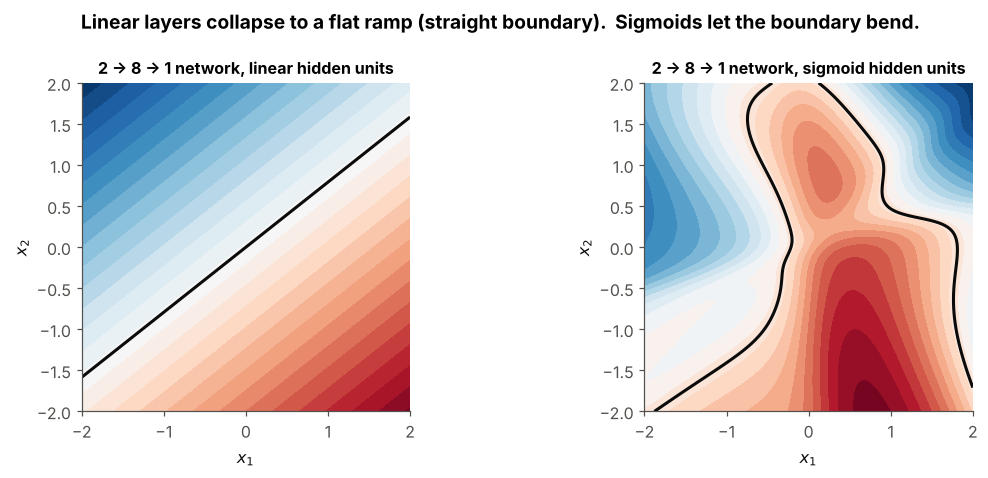

In [3]:
def sigmoid(z):
    """σ(z) = 1 / (1 + e^{-z})  — squashes any real number into (0, 1)."""
    return 1.0 / (1.0 + np.exp(-z))

rng = np.random.default_rng(3)
A1, c1 = rng.normal(0, 3, (8, 2)), rng.normal(0, 2, (8, 1))   # hidden layer: 8 neurons
A2, c2 = rng.normal(0, 3, (1, 8)), rng.normal(0, 1, (1, 1))   # output layer: 1 neuron

g = np.linspace(-2, 2, 300); xx, yy = np.meshgrid(g, g)
P = np.vstack([xx.ravel(), yy.ravel()])                        # every pixel as a column (2, 90000)

fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.4))
for ax, (name, act) in zip(axs, [("linear hidden units", lambda z: z), ("sigmoid hidden units", sigmoid)]):
    out = (A2 @ act(A1 @ P + c1) + c2).reshape(xx.shape)       # same weights, different activation
    ax.contourf(xx, yy, out, levels=30, cmap="RdBu_r")
    ax.contour(xx, yy, out, levels=[np.median(out)], colors=C["ink"], linewidths=2)
    ax.set_title(f"2 → 8 → 1 network, {name}", fontsize=10.5); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
fig.suptitle("Linear layers collapse to a flat ramp (straight boundary).  Sigmoids let the boundary bend.", fontweight="bold")
plt.tight_layout(); plt.show()

---
## 3 · What we need from an activation function ✅

From the notes, the activation must be:

| Requirement | Why | Step | Linear | Sigmoid |
|---|---|---|---|---|
| **Non-linear** | otherwise layers collapse (section 2) | ✅ | ❌ | ✅ |
| **Continuous and differentiable** | gradient descent needs a slope | ❌ | ✅ | ✅ |
| **Step-like** ("simulate activation of neuron") | a neuron "fires" or "doesn't" | ✅ | ❌ | ✅ |

Only the sigmoid ticks all three boxes.

---
## 4 · The sigmoid function 〰️

$$\boxed{\sigma(x)=\frac{1}{1+e^{-x}}}$$

| $x$ | −5 | −2 | −1 | 0 | 1 | 2 | 5 |
|---|---|---|---|---|---|---|---|
| $\sigma(x)$ | 0.007 | 0.119 | 0.269 | **0.5** | 0.731 | 0.881 | 0.993 |

**Read it as a "soft yes/no":** very negative input → almost 0 (NO), very positive → almost 1 (YES), around 0 → unsure (0.5). Its output can also be read as a **probability**.

### Its derivative: $\sigma'(x)=y(1-y)$ — derived step by step
Let $y=\sigma(x)=(1+e^{-x})^{-1}$.

$$\begin{aligned} \frac{dy}{dx}&=-1\cdot(1+e^{-x})^{-2}\cdot\frac{d}{dx}(1+e^{-x}) &&\text{chain rule on }u^{-1}\cr &=-(1+e^{-x})^{-2}\cdot(-e^{-x})=\frac{e^{-x}}{(1+e^{-x})^2}\cr &=\underbrace{\frac{1}{1+e^{-x}}}_{y}\cdot\underbrace{\frac{e^{-x}}{1+e^{-x}}}_{1-y} &&\text{since }1-y=\frac{(1+e^{-x})-1}{1+e^{-x}}\cr &=\boxed{\ y\ (1-y)\ } \end{aligned}$$

**Why this is wonderful:** once the forward pass has computed $y$, the slope costs just **one multiplication** – no new exponentials. Backpropagation (module 02) uses this trick millions of times.

max |y(1-y) - numerical slope| = 1.4095037637051888e-11
values: {-5: 0.007, -2: 0.119, -1: 0.269, 0: 0.5, 1: 0.731, 2: 0.881, 5: 0.993}


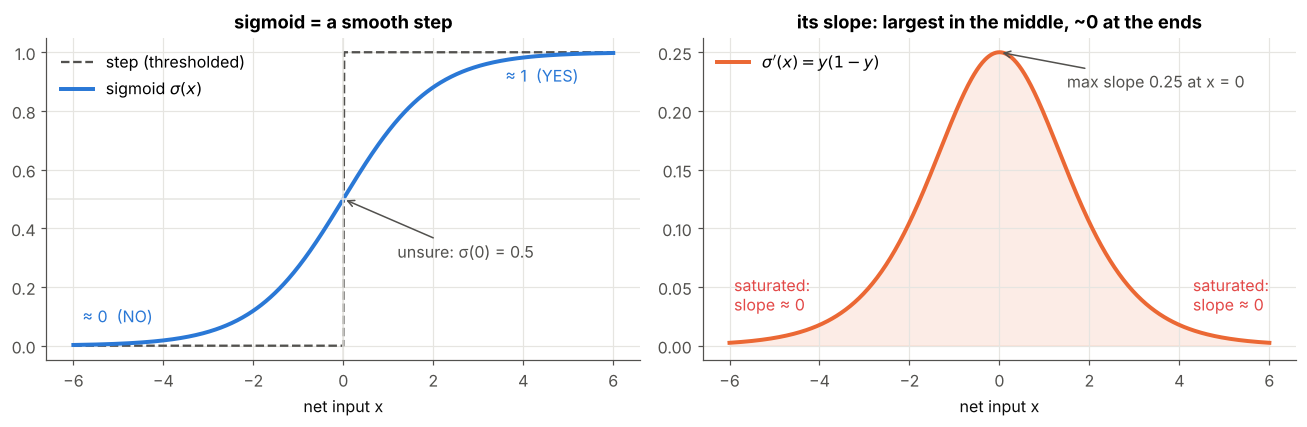

In [4]:
def sigmoid_derivative_from_output(y):
    """σ'(x) written in terms of the OUTPUT y = σ(x):  y (1 - y)."""
    return y * (1.0 - y)

x = np.linspace(-6, 6, 601)
y = sigmoid(x)

# check the formula against a numerical slope
h = 1e-5
numeric = (sigmoid(x + h) - sigmoid(x - h)) / (2 * h)
print("max |y(1-y) - numerical slope| =", np.abs(sigmoid_derivative_from_output(y) - numeric).max())
print("values:", {v: round(float(sigmoid(v)), 3) for v in [-5, -2, -1, 0, 1, 2, 5]})

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ax = axs[0]
ax.plot(x, np.where(x > 0, 1, 0), color=C["muted"], lw=1.5, ls="--", label="step (thresholded)")
ax.plot(x, y, color=C["blue"], lw=2.6, label=r"sigmoid $\sigma(x)$")
ax.axhline(0.5, color=C["grid"], lw=1); ax.axvline(0, color=C["grid"], lw=1)
ax.annotate("unsure: σ(0) = 0.5", xy=(0, 0.5), xytext=(1.2, 0.3), arrowprops=dict(arrowstyle="->", color=C["muted"]), color=C["muted"])
ax.text(-5.8, 0.08, "≈ 0  (NO)", color=C["blue"]); ax.text(3.6, 0.9, "≈ 1  (YES)", color=C["blue"])
ax.set_title("sigmoid = a smooth step"); ax.set_xlabel("net input x"); ax.legend(loc="upper left")

ax = axs[1]
ax.plot(x, sigmoid_derivative_from_output(y), color=C["orange"], lw=2.6, label=r"$\sigma'(x)=y(1-y)$")
ax.fill_between(x, 0, sigmoid_derivative_from_output(y), color=C["orange"], alpha=0.12)
ax.annotate("max slope 0.25 at x = 0", xy=(0, 0.25), xytext=(1.5, 0.22), arrowprops=dict(arrowstyle="->", color=C["muted"]), color=C["muted"])
ax.text(-5.9, 0.03, "saturated:\nslope ≈ 0", color=C["red"]); ax.text(4.3, 0.03, "saturated:\nslope ≈ 0", color=C["red"])
ax.set_title("its slope: largest in the middle, ~0 at the ends"); ax.set_xlabel("net input x"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### The sigmoid *contains* the step
Scaling the input, $\sigma(k\ x)$, makes the curve steeper. As $k\to\infty$ it becomes the step function – so the sigmoid neuron is a **generalisation** of the perceptron that can be as sharp or as soft as the weights decide.

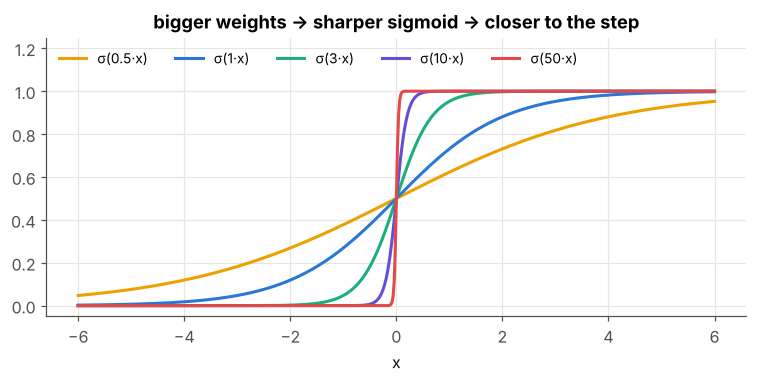

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, col in zip([0.5, 1, 3, 10, 50], [C["yellow"], C["blue"], C["aqua"], C["violet"], C["red"]]):
    ax.plot(x, sigmoid(k * x), color=col, label=f"σ({k}·x)")
ax.set_title("bigger weights → sharper sigmoid → closer to the step"); ax.set_xlabel("x"); ax.legend(ncol=5, loc="upper left", fontsize=9)
ax.set_ylim(-0.05, 1.25)
plt.tight_layout(); plt.show()

---
## 5 · Gradient descent for a sigmoid unit 🎯

The unit computes $o_d=\sigma(net_d)$ with $net_d=\vec w\cdot\vec x_d$, and we minimise the same cost $E=\tfrac12\sum_d(t_d-o_d)^2$.

### Derivation (one more link in the chain than notebook 02)

$$\frac{\partial E}{\partial w_i} =\sum_d \underbrace{\frac{\partial E}{\partial o_d}}_{-(t_d-o_d)}\cdot \underbrace{\frac{\partial o_d}{\partial net_d}}_{o_d(1-o_d)}\cdot \underbrace{\frac{\partial net_d}{\partial w_i}}_{x_{i,d}}$$

$$\boxed{\frac{\partial E}{\partial w_i}=-\sum_d (t_d-o_d)\ o_d(1-o_d)\ x_{i,d}}\qquad \boxed{\Delta w_i=\eta\sum_d (t_d-o_d)\ o_d(1-o_d)\ x_{i,d}}$$

Compare with the delta rule: the only new factor is $o_d(1-o_d)$, the sigmoid's slope. The notes point this out too: *"Activation function changes, only this partial derivative changes."*

It's convenient to name the product of the first two factors: $\delta_d=(t_d-o_d)\ o_d(1-o_d)$ – the **error term** of the unit. Then $\Delta w_i=\eta\sum_d\delta_d\ x_{i,d}$. Module 02 is built entirely around these $\delta$'s.

In [6]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))                    # σ(z) ∈ (0, 1)


class SigmoidNeuron:
    """o = σ(w·x), trained by batch gradient descent on E = 1/2 Σ_d (t_d - o_d)^2."""

    def __init__(self, learning_rate=0.5, epochs=1000, seed=0):
        self.eta, self.epochs = learning_rate, epochs
        self.rng = np.random.default_rng(seed)

    @staticmethod
    def add_bias(X):
        return np.c_[np.ones((X.shape[0], 1)), X]       # x0 = 1

    def fit(self, X, t):
        Xb = self.add_bias(X)
        self.w = self.rng.normal(0, 0.5, Xb.shape[1])  # small random start
        self.loss_history = []
        for _ in range(self.epochs):
            o = sigmoid(Xb @ self.w)                    # forward: o_d = σ(net_d)
            self.loss_history.append(0.5 * np.sum((t - o) ** 2))   # E(w)
            delta = (t - o) * o * (1 - o)               # δ_d = (t_d - o_d) o_d (1 - o_d)
            self.w += self.eta * Xb.T @ delta           # Δw_i = η Σ_d δ_d x_id
        return self

    def predict_proba(self, X):
        return sigmoid(self.add_bias(X) @ self.w)

### 🔍 Walk-through
| Code | Maths |
|---|---|
| `o = sigmoid(Xb @ self.w)` | $o_d=\sigma(\vec w\cdot\vec x_d)$ for all $d$ at once |
| `delta = (t - o) * o * (1 - o)` | $\delta_d=(t_d-o_d)\ o_d(1-o_d)$ – elementwise products |
| `Xb.T @ delta` | $\sum_d\delta_d\ x_{i,d}$ for every weight $i$ |
| `self.w += self.eta * ...` | $w_i\leftarrow w_i+\eta\sum_d\delta_dx_{i,d}$ |

Note: targets are now **0/1** (not ±1), because the sigmoid's outputs live in $(0,1)$.

### Learning the OR gate

In [7]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
t_or = np.array([0, 1, 1, 1.0])

neuron = SigmoidNeuron(learning_rate=0.5, epochs=2000).fit(X_gate, t_or)
print("learned w =", neuron.w)
print("outputs   =", neuron.predict_proba(X_gate), "  targets:", t_or)
print(f"E: start {neuron.loss_history[0]:.3f} → end {neuron.loss_history[-1]:.4f}")

learned w = [-2.8436  6.1796  6.1796]
outputs   = [0.055  0.9656 0.9656 0.9999]   targets: [0. 1. 1. 1.]
E: start 0.429 → end 0.0027


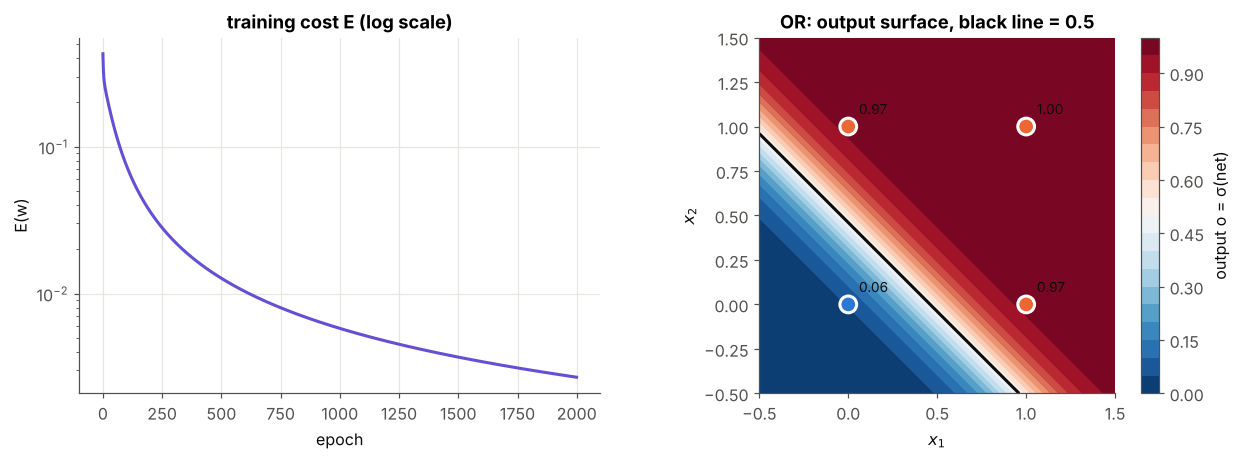

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.3))
axs[0].plot(neuron.loss_history, color=C["violet"])
axs[0].set_yscale("log"); axs[0].set_title("training cost E (log scale)"); axs[0].set_xlabel("epoch"); axs[0].set_ylabel("E(w)")

g = np.linspace(-0.5, 1.5, 300); xx, yy = np.meshgrid(g, g)
pp = neuron.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
im = axs[1].contourf(xx, yy, pp, levels=20, cmap="RdBu_r", vmin=0, vmax=1)
axs[1].contour(xx, yy, pp, levels=[0.5], colors=C["ink"], linewidths=2)
axs[1].scatter(X_gate[:, 0], X_gate[:, 1], c=t_or.astype(int), cmap=POINT_CMAP, s=120, edgecolor="white", linewidth=2, zorder=3)
for (a, b), p in zip(X_gate, neuron.predict_proba(X_gate)):
    axs[1].text(a + 0.06, b + 0.07, f"{p:.2f}", fontsize=9, color=C["ink"])
plt.colorbar(im, ax=axs[1], label="output o = σ(net)")
axs[1].set_title("OR: output surface, black line = 0.5"); axs[1].set_aspect("equal"); axs[1].grid(False)
axs[1].set_xlabel("$x_1$"); axs[1].set_ylabel("$x_2$")
plt.tight_layout(); plt.show()

The output is now a **smooth confidence** instead of a hard ±1. But look at the black 0.5-line: it is still **straight**. A single sigmoid unit still separates the plane with one line.

---
## 6 · XOR: one sigmoid still fails, one hidden layer succeeds 🧩

> ⚠️ **Common misconception:** "the sigmoid is non-linear, so a sigmoid neuron can learn XOR." **False.** $\sigma$ is monotonic, so $\sigma(net)>0.5 \iff net>0$ – the boundary is still the straight line $net=0$. The non-linearity only pays off when units are **stacked**.

In [9]:
t_xor = np.array([0, 1, 1, 0.0])
single = SigmoidNeuron(learning_rate=0.5, epochs=5000).fit(X_gate, t_xor)
print("single sigmoid on XOR → outputs", single.predict_proba(X_gate), "(stuck near 0.5 = 'no idea')")

single sigmoid on XOR → outputs [0.5 0.5 0.5 0.5] (stuck near 0.5 = 'no idea')


### A hand-built 2-2-1 network that computes XOR
XOR = (x₁ OR x₂) AND NOT(x₁ AND x₂) = **AND( OR, NAND )**. Each of OR, NAND and AND is a single straight line, so each is one sigmoid unit:

| unit | weights $(w_0,w_1,w_2)$ | computes |
|---|---|---|
| hidden $h_1$ | $(-10,\ 20,\ 20)$ | OR |
| hidden $h_2$ | $(30,\ -20,\ -20)$ | NAND |
| output $o$ | $(-30,\ 20,\ 20)$ on $(1,h_1,h_2)$ | AND of $h_1,h_2$ |

The hidden layer **re-maps** the four points into a new space $(h_1,h_2)$ where XOR becomes linearly separable.

x = [0 0]  →  h = (0.000, 1.000)  →  o = 0.0000
x = [0 1]  →  h = (1.000, 1.000)  →  o = 1.0000
x = [1 0]  →  h = (1.000, 1.000)  →  o = 1.0000
x = [1 1]  →  h = (1.000, 0.000)  →  o = 0.0000


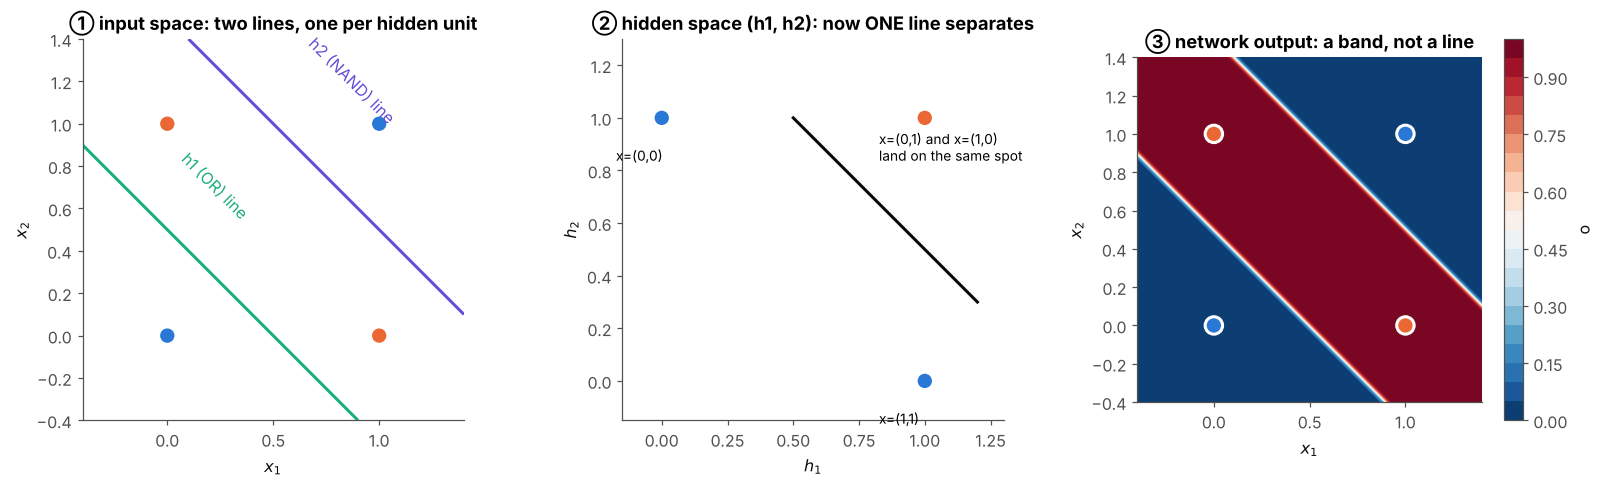

In [10]:
def xor_net(X):
    """Hand-wired 2-2-1 sigmoid network. Returns hidden outputs and final output."""
    h1 = sigmoid(-10 + 20 * X[:, 0] + 20 * X[:, 1])        # ≈ OR
    h2 = sigmoid(30 - 20 * X[:, 0] - 20 * X[:, 1])         # ≈ NAND
    o = sigmoid(-30 + 20 * h1 + 20 * h2)                   # ≈ AND(h1, h2)
    return np.c_[h1, h2], o

H, o_xor = xor_net(X_gate)
for x_, h_, o_ in zip(X_gate, H, o_xor):
    print(f"x = {x_.astype(int)}  →  h = ({h_[0]:.3f}, {h_[1]:.3f})  →  o = {o_:.4f}")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
g = np.linspace(-0.4, 1.4, 300); xx, yy = np.meshgrid(g, g); G = np.c_[xx.ravel(), yy.ravel()]
# (1) input space with the two hidden-unit lines
ax = axs[0]
ax.contour(xx, yy, (-10 + 20 * xx + 20 * yy), levels=[0], colors=C["aqua"], linewidths=2)
ax.contour(xx, yy, (30 - 20 * xx - 20 * yy), levels=[0], colors=C["violet"], linewidths=2)
ax.scatter(X_gate[:, 0], X_gate[:, 1], c=t_xor.astype(int), cmap=POINT_CMAP, s=130, edgecolor="white", linewidth=2, zorder=3)
ax.text(0.05, 0.55, "h1 (OR) line", color=C["aqua"], rotation=-45); ax.text(0.65, 1.0, "h2 (NAND) line", color=C["violet"], rotation=-45)
ax.set_title("① input space: two lines, one per hidden unit"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
# (2) hidden space
ax = axs[1]
ax.plot([0.5, 1.2], [1.0, 0.3], color=C["ink"], lw=2)                       # output unit's line h1 + h2 = 1.5
ax.scatter(H[:, 0], H[:, 1], c=t_xor.astype(int), cmap=POINT_CMAP, s=130, edgecolor="white", linewidth=2, zorder=3)
for txt, pos in [("x=(0,0)", H[0]), ("x=(0,1) and x=(1,0)\nland on the same spot", H[1]), ("x=(1,1)", H[3])]:
    ax.annotate(txt, pos, textcoords="offset points", xytext=(-30, -28), fontsize=9)
ax.set_xlim(-0.15, 1.3); ax.set_ylim(-0.15, 1.3)
ax.set_title("② hidden space (h1, h2): now ONE line separates"); ax.set_xlabel("$h_1$"); ax.set_ylabel("$h_2$")
# (3) final output
ax = axs[2]
_, oo = xor_net(G)
im = ax.contourf(xx, yy, oo.reshape(xx.shape), levels=20, cmap="RdBu_r", vmin=0, vmax=1)
ax.scatter(X_gate[:, 0], X_gate[:, 1], c=t_xor.astype(int), cmap=POINT_CMAP, s=130, edgecolor="white", linewidth=2, zorder=3)
plt.colorbar(im, ax=ax, label="o")
ax.set_title("③ network output: a band, not a line"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
for a in axs: a.set_aspect("equal"); a.grid(False)
plt.tight_layout(); plt.show()

This is the key idea of deep learning in one picture: **each layer re-represents the data so the next layer's job gets easier.**

Here we *chose* the hidden weights by hand. The open question – *"how do we learn the hidden weights from data?"* – is exactly what **backpropagation** answers in module 02.

---
## 7 · A warning sign: saturation and the vanishing gradient ⚠️

$\sigma'(x)=y(1-y)$ is at most **0.25**, and almost **0** when the unit is saturated ($y\approx0$ or $1$). In a deep network the gradient is a product of one such factor per layer, so it shrinks fast:

after 10 layers, best case: 9.5367431640625e-07


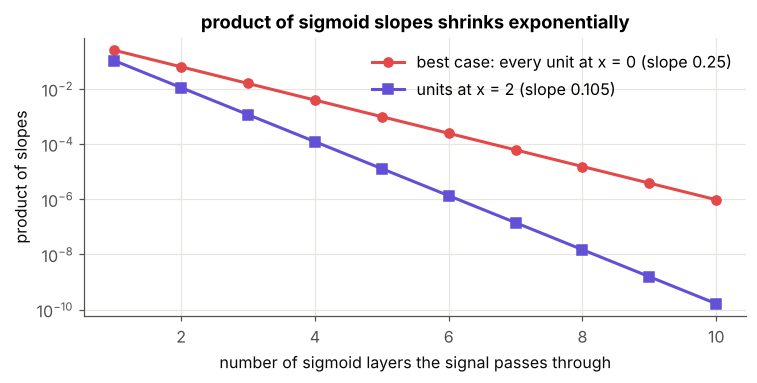

In [11]:
layers = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(layers, 0.25 ** layers, "o-", color=C["red"], label="best case: every unit at x = 0 (slope 0.25)")
ax.semilogy(layers, (sigmoid(2) * (1 - sigmoid(2))) ** layers, "s-", color=C["violet"], label="units at x = 2 (slope 0.105)")
ax.set_xlabel("number of sigmoid layers the signal passes through"); ax.set_ylabel("product of slopes")
ax.set_title("product of sigmoid slopes shrinks exponentially"); ax.legend()
plt.tight_layout(); plt.show()
print("after 10 layers, best case:", 0.25 ** 10)

That is the **vanishing gradient problem**. It is why modern networks often use ReLU in hidden layers, and why LSTMs (module 06) were invented. We will measure it for real in module 02.

---
## 8 · Summary 📌

| | Thresholded perceptron | Linear unit (delta rule) | Sigmoid unit |
|---|---|---|---|
| Output | $\text{sgn}(\vec w\cdot\vec x)\in\lbrace \pm1\rbrace $ | $\vec w\cdot\vec x\in\mathbb R$ | $\sigma(\vec w\cdot\vec x)\in(0,1)$ |
| Differentiable? | ❌ | ✅ | ✅ |
| Useful when stacked? | can't be trained | ❌ collapses | ✅ |
| Update $\Delta w_i$ | $\eta(t-o)x_i$ | $\eta\sum_d(t_d-o_d)x_{i,d}$ | $\eta\sum_d(t_d-o_d)\ o_d(1-o_d)\ x_{i,d}$ |
| XOR with one unit? | ❌ | ❌ | ❌ (needs a hidden layer) |

**Key formulas:** $\sigma(x)=\dfrac1{1+e^{-x}}$, $\quad\sigma'(x)=y(1-y)$, $\quad\delta=(t-o)\ o(1-o)$.

### ✍️ Try it yourself
1. Replace the sigmoid by $\tanh$ (output in $(-1,1)$, derivative $1-y^2$) and retrain OR with ±1 targets.
2. In `xor_net`, divide every weight by 10. What happens to the outputs, and why? *(Hint: section 4, $\sigma(kx)$.)*
3. Train `SigmoidNeuron` on AND starting from huge weights, e.g. `w = [-50, 1, 1]`. Why is learning so slow at first? *(Saturation!)*
4. Prove that $1-\sigma(x)=\sigma(-x)$.

**Next module →** `02 - Feed-Forward Networks and Backpropagation`: learn the hidden weights automatically.